# LensScribe — Image Captioning with GLM-OCR
### AI that reads and describes the text it sees in an image!
---
**Model:** zai-org/GLM-OCR

> **GLM-OCR = a 0.9B-parameter vision-language model for reading documents**
> You give it an image → it writes out what it reads!

**Examples:**
- Photo of a receipt → *'Coffee 3.50, Sandwich 6.25, Total 9.75'*
- Photo of a sign    → *'OPEN 9 AM – 6 PM'*
- Photo of a table   → *a clean table of rows and columns*

> **Note:** GLM-OCR is trained to *read* images (text, formulas, tables) — it is not a
> scene captioner like BLIP. So here the **caption = the text the model reads in the image.**

---
## Step 1 — Install and load GLM-OCR

> GLM-OCR needs a very recent version of `transformers`, so we install it from GitHub.
> In Colab: **Runtime → Change runtime type → T4 GPU** makes it much faster.

In [ ]:
!pip install git+https://github.com/huggingface/transformers.git gradio pillow accelerate -q

import torch
from transformers import AutoProcessor, AutoModelForImageTextToText
from transformers.utils import logging
import warnings
warnings.filterwarnings('ignore')
logging.set_verbosity_error()

MODEL_PATH = 'zai-org/GLM-OCR'

print('Loading GLM-OCR model...')
processor = AutoProcessor.from_pretrained(MODEL_PATH)
ocr_model = AutoModelForImageTextToText.from_pretrained(
                MODEL_PATH,
                torch_dtype = 'auto',
                device_map  = 'auto')
print('GLM-OCR ready!')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Loading GLM-OCR model...


Loading weights:   0%|          | 0/510 [00:00<?, ?it/s]

GLM-OCR ready!


---
## Step 2 — Get a sample image

> We try to download a reliable sample image.
> If that fails — a test image with text is created automatically.
> In the Gradio app you can upload YOUR OWN photo!

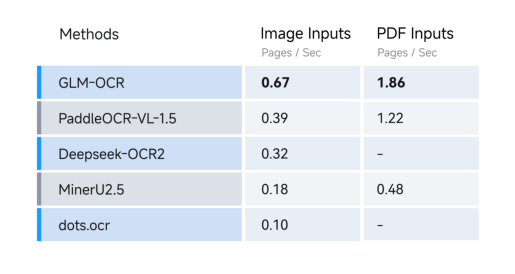

Image size: (1758, 903)


In [ ]:
import requests
from PIL import Image, ImageDraw, ImageFont
from io import BytesIO
import matplotlib.pyplot as plt

def make_test_image():
    # Fallback: draw a small receipt-style image that contains real text
    img  = Image.new('RGB', (900, 420), 'white')
    draw = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 36)
    except Exception:
        font = ImageFont.load_default()
    lines = ['LENSSCRIBE CAFE', 'Coffee ........... 3.50',
             'Sandwich ......... 6.25', 'TOTAL ............ 9.75',
             'Thank you! Visit again.']
    for i, line in enumerate(lines):
        draw.text((40, 30 + i * 70), line, fill='black', font=font)
    return img

# Download an image
url = "https://raw.githubusercontent.com/zai-org/GLM-OCR/refs/heads/main/resources/speed.png"

try:
    response = requests.get(url, timeout=20)
    response.raise_for_status()
    image = Image.open(BytesIO(response.content)).convert("RGB")
except Exception as e:
    print("Download failed, using a generated test image:", e)
    image = make_test_image()

# Display the image
plt.imshow(image)
plt.axis("off")
plt.show()

# Print image size
print("Image size:", image.size)

---
## Step 3 — Create the caption function

> This function takes an image and returns the text GLM-OCR reads.
> Same idea as the translate() and summarize() functions we built before!

In [ ]:
def get_caption(image, max_new_tokens=512):
    # Step A: prepare the image + instruction for GLM-OCR
    messages = [{
        'role': 'user',
        'content': [
            {'type': 'image', 'image': image.convert('RGB')},
            {'type': 'text',  'text': 'Text Recognition:'}
        ]
    }]
    inputs = processor.apply_chat_template(
                 messages,
                 tokenize              = True,
                 add_generation_prompt = True,
                 return_dict           = True,
                 return_tensors        = 'pt').to(ocr_model.device)
    inputs.pop('token_type_ids', None)

    # Step B: generate the caption
    with torch.no_grad():
        output = ocr_model.generate(**inputs, max_new_tokens=max_new_tokens)

    # Step C: convert numbers back to text (keep only the NEW tokens)
    new_tokens = output[0][inputs['input_ids'].shape[1]:]
    caption = processor.decode(new_tokens, skip_special_tokens=True)
    return caption.strip()

print('get_caption() function ready!')

get_caption() function ready!


---
## Step 4 — Generate your first caption!

> Look at the image above.
> Write what YOU think the text says.
> Then run this cell — see if GLM-OCR agrees!

In [ ]:
import torch

caption = get_caption(image)

print("GLM-OCR says:")
print(f'  "{caption}"')
print()
print(f"Word count: {len(caption.split())} words")

GLM-OCR says:
  "Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR 0.67 1.86
PaddleOCR-VL-1.5 0.39 1.22
Deepseek-OCR2 0.32 –
MinerU2.5 0.18 0.48
dots.ocr 0.10 –"

Word count: 26 words


PyTorch (torch) is a Python library used to build, train, and run Artificial Intelligence (AI) and Machine Learning (ML) models.
In your GLM-OCR image captioning project, torch helps the model process an image and generate the text it reads.

---
## Step 5 — Guide the caption with a prompt

> GLM-OCR does not complete free-form sentences like BLIP.
> Instead you pick the **task prompt** that tells it what to read.

> Supported prompts: `Text Recognition:`, `Formula Recognition:`, `Table Recognition:`

In [ ]:
def get_caption_with_prompt(image, prompt, max_new_tokens=512):
    # Same as before — but we choose the task prompt
    messages = [{
        'role': 'user',
        'content': [
            {'type': 'image', 'image': image.convert('RGB')},
            {'type': 'text',  'text': prompt}
        ]
    }]
    inputs = processor.apply_chat_template(
                 messages,
                 tokenize              = True,
                 add_generation_prompt = True,
                 return_dict           = True,
                 return_tensors        = 'pt').to(ocr_model.device)
    inputs.pop('token_type_ids', None)
    with torch.no_grad():
        output = ocr_model.generate(**inputs, max_new_tokens=max_new_tokens)
    new_tokens = output[0][inputs['input_ids'].shape[1]:]
    return processor.decode(new_tokens, skip_special_tokens=True).strip()


# Same image — different task prompts
prompts = [
    'Text Recognition:',
    'Formula Recognition:',
    'Table Recognition:',
]

print('Same image — different prompts:')
print()
for prompt in prompts:
    result = get_caption_with_prompt(image, prompt)
    print(f'Prompt  : "{prompt}"')
    print(f'Caption : "{result}"')
    print()

Same image — different prompts:

Prompt  : "Text Recognition:"
Caption : "Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR 0.67 1.86
PaddleOCR-VL-1.5 0.39 1.22
Deepseek-OCR2 0.32 –
MinerU2.5 0.18 0.48
dots.ocr 0.10 –"

Prompt  : "Formula Recognition:"
Caption : "$$
\begin{array}{l l l} \mathrm {M a t h e d s} & \mathrm {I m a g e I n p u t s} & \mathrm {P D F I n p u t s} \\ & \mathrm {P a p e s s / S e c} & \mathrm {P a p e s s / S e c} \\ \mathrm {G L M - O C R} & 0. 6 7 & 1. 8 6 \\ \mathrm {P a d d l e O C R - V L - 1. 5} & 0. 3 9 & 1. 2 2 \\ \mathrm {D e e p s e e k - O C R 2} & 0. 3 2 & - \\ \mathrm {M i n e r U 2. 5} & 0. 1 8 & 0. 4 8 \\ \mathrm {d o t s. o c r} & 0. 1 0 & - \end{array}
$$"

Prompt  : "Table Recognition:"
Caption : "<table border="1"><tr><td>Methods</td><td>Image InputsPages/Sec</td><td>PDF InputsPages/Sec</td></tr><tr><td>GLM-OCR</td><td>0.67</td><td>1.86</td></tr><tr><td>PaddleOCR-VL-1.5</td><td>0.39</td><td>1.22</td></tr><tr><td>Deepseek-OCR2</t

---
## Step 7 — How does max_new_tokens affect the caption?

> More tokens = longer output allowed.
> Let's see the difference!

In [ ]:
import pandas as pd

token_lengths = [20, 40, 60, 80]
results = []

for max_t in token_lengths:
    cap   = get_caption(image, max_new_tokens=max_t)
    words = len(cap.split())
    results.append({'max_tokens': max_t, 'words': words, 'caption': cap})
    print(f'max_tokens={max_t:3d} → {words} words: {cap}')

print()
print('More tokens = longer caption')
print('But after a point the caption does not grow much more')

max_tokens= 20 → 12 words: Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR
max_tokens= 40 → 15 words: Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR 0.67 1.86
PaddleOCR-VL-1.
max_tokens= 60 → 18 words: Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR 0.67 1.86
PaddleOCR-VL-1.5 0.39 1.22
Deepseek-OCR2
max_tokens= 80 → 23 words: Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR 0.67 1.86
PaddleOCR-VL-1.5 0.39 1.22
Deepseek-OCR2 0.32 –
MinerU2.5 0.18 0.

More tokens = longer caption
But after a point the caption does not grow much more


## MULTIPLE IMAGES

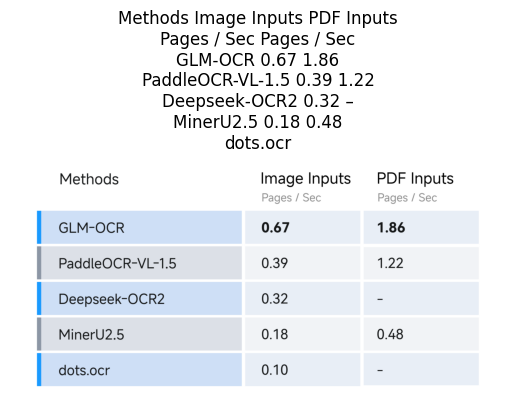

Caption: Methods Image Inputs PDF Inputs
Pages / Sec Pages / Sec
GLM-OCR 0.67 1.86
PaddleOCR-VL-1.5 0.39 1.22
Deepseek-OCR2 0.32 –
MinerU2.5 0.18 0.48
dots.ocr 0.10 –
Error: CUDA out of memory. Tried to allocate 35.49 GiB. GPU 0 has a total capacity of 14.56 GiB of which 10.34 GiB is free. Including non-PyTorch memory, this process has 4.22 GiB memory in use. Of the allocated memory 3.20 GiB is allocated by PyTorch, and 913.74 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)


In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

urls = [
    "https://raw.githubusercontent.com/zai-org/GLM-OCR/refs/heads/main/resources/speed.png",
    "https://raw.githubusercontent.com/zai-org/GLM-OCR/refs/heads/main/resources/realworld.png"
]

for url in urls:
    try:
        # Download and open image
        img = Image.open(BytesIO(requests.get(url).content)).convert("RGB")

        # Generate caption using GLM-OCR
        caption = get_caption(img)

        # Display image and caption
        plt.imshow(img)
        plt.axis("off")
        plt.title(caption[:150], wrap=True)
        plt.show()

        print("Caption:", caption)

    except Exception as e:
        print("Error:", e)

requests.get(url) downloads the image.

.content gets the downloaded image data.

BytesIO() lets PIL read that data as a file.

Image.open() opens the image.

.convert("RGB") ensures it uses the standard three color channels.

---
## Step 8 — Build a Gradio Caption App

> Upload ANY photo from your phone.
> Choose a task prompt.
> AI reads the image instantly!

In [ ]:
import gradio as gr

def caption_app(uploaded_image, prompt):
    if uploaded_image is None:
        return 'Please upload an image first!'

    img = uploaded_image.convert('RGB')

    # Use the chosen task prompt, otherwise plain text recognition
    if prompt and prompt.strip():
        caption = get_caption_with_prompt(img, prompt)
    else:
        caption = get_caption(img)

    word_count = len(caption.split())
    return f'Caption:\n"{caption}"\n\nWords: {word_count}'


app = gr.Interface(
    fn      = caption_app,
    inputs  = [
        gr.Image(
            type  = 'pil',
            label = 'Upload any image'
        ),
        gr.Dropdown(
            choices = ['Text Recognition:', 'Formula Recognition:', 'Table Recognition:'],
            value   = 'Text Recognition:',
            label   = 'Task prompt'
        )
    ],
    outputs     = gr.Textbox(label='AI Caption', lines=8),
    title       = 'LensScribe — Image Captioning with GLM-OCR',
    description = 'Upload any image — AI reads it and writes out the text!'
)

app.launch(share=True)

In [ ]:
app.close()
print('App closed.')

---
## What we learned today

| Step | What we did |
|------|-------------|
| 1 | Loaded GLM-OCR model |
| 2 | Got a sample image |
| 3 | Created get_caption() function |
| 4 | Generated first caption |
| 5 | Used different task prompts |
| 7 | Compared different token lengths |
| — | Captioned multiple images |
| 8 | Built Gradio caption app |

### Key words:
- **GLM-OCR** — AI model that reads text, formulas and tables from images
- **Caption** — the text the model writes out for the image
- **Prompt** — a task instruction (e.g. `Text Recognition:`) that guides the model
- **max_new_tokens** — controls how long the output can be

**Next — Smart Document Reader:** Combine GLM-OCR with a layout detector
to find AND read every section of a document!